In [46]:
import re
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, make_scorer, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import seaborn as sns

In [47]:
llm_df = pd.read_csv("llm_hallucination_dataset_v1.csv")
llm_df = llm_df.drop(columns=["notes"])

In [48]:
def light_clean(text):
    text = str(text).strip()
    text = re.sub(r"\s+", " ", text)
    text = text.lower()
    return text

llm_df["text"] = (
    "question: " + llm_df["prompt_text"].astype(str) + 
    " answer: " + llm_df["response_text"].astype(str)
).map(light_clean)

y = llm_df["hallucination_label"]
groups = llm_df["prompt_text"]
X = llm_df["text"] 

In [49]:
unique_prompts = llm_df["prompt_text"].unique()

train_prompts, test_prompts = train_test_split(unique_prompts, test_size=0.2, random_state=1)

train_mask = llm_df["prompt_text"].isin(train_prompts)
test_mask = llm_df["prompt_text"].isin(test_prompts)

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]
g_train = groups[train_mask]

In [50]:
pipeline = Pipeline(
    steps=[
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
        ("lr", LogisticRegression(max_iter=1000, random_state=1)),
    ]
)

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

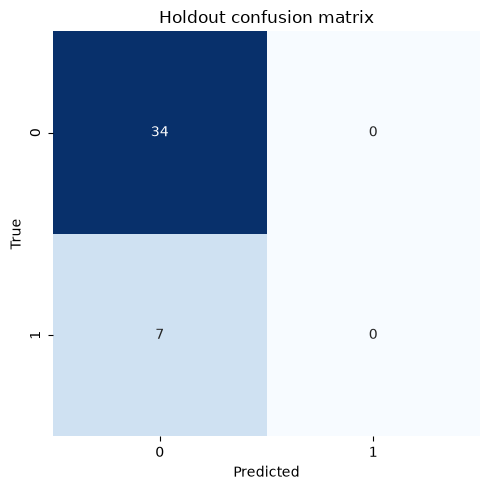

              precision    recall  f1-score   support

           0      0.829     1.000     0.907        34
           1      0.000     0.000     0.000         7

    accuracy                          0.829        41
   macro avg      0.415     0.500     0.453        41
weighted avg      0.688     0.829     0.752        41



In [51]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[0, 1],
    yticklabels=[0, 1],
    ax=ax,
)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Holdout confusion matrix")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, digits=3, zero_division=0))

In [52]:
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=1)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}
cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    groups=g_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
)

for metric in ["test_accuracy", "test_precision", "test_recall", "test_f1"]:
    print(f"3-fold average {metric}: {cv_results[metric].mean():.3f}")

3-fold average test_accuracy: 0.642
3-fold average test_precision: 0.242
3-fold average test_recall: 0.133
3-fold average test_f1: 0.172
